SAME as neural network_6 but:

- random shuffle without replacement!
- only retained the new version of the neural network, using the delta method for backpropagation

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
import time
import random

In [2]:
def sigma(x):
    s = 1/(1 + np.exp(-x))
    return s

def sigma_der(x):
    s = np.exp(-x)/(1+np.exp(-x))**2
    return s

In [3]:
def det_activations(inputs, weights, biases):
    
    activations = []
    activations.append(np.dot(weights[0],inputs) + biases[0])
    
    for i in range(1,len(biases)):

        activations.append(np.dot(weights[i],activations[i-1]) + biases[i])

    activations = [sigma(act) for act in activations]
    activations = [np.round(act, 3) for act in activations]
        
    return activations

In [4]:
def grad(act, wt, bs, ins, outs):
    
    delta = [0*a for a in act]
    gr_bs = [0*b for b in bs]
    gr_wt = [0*w for w in wt]

    L = len(act)

    delta[-1] = 2*(act[-1] - outs) * sigma_der(np.dot(wt[-1], act[-2]) + bs[-1])

    for i in range(2,L):
        delta[-i] = np.dot(wt[-i+1].T, delta[-i+1]) * sigma_der(np.dot(wt[-i], act[-i-1]) + bs[-i])

    delta[-L] = np.dot(wt[-L+1].T, delta[-L+1]) * sigma_der(np.dot(wt[-L], ins) + bs[-L])

    gr_bs = delta

    for j in range(len(act[0])):
        for k in range(len(ins)):
            gr_wt[0][j][k] = ins[k] * delta[0][j]
    
    for l in range(1,L):
        for j in range(len(act[l])):
            for k in range(len(act[l-1])):
                gr_wt[l][j][k] = act[l-1][k] * delta[l][j]
                
    
    return gr_wt, gr_bs

In [5]:
def neural_network(inputs, outputs, nodes, learning_rate, epochs, batch_size):

    #device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
    #print(f"Using device: {device}")
          
    nodes.append(outputs.shape[1])
    nodes.insert(0, inputs.shape[1])
    
    biases = [np.random.randn(y) for y in nodes[1:]]
    weights = [np.random.randn(x, y) for x, y in zip(nodes[1:], nodes[:-1])]

    #biases = [np.random.uniform(-1, 1, y) for y in nodes[1:]]
    #weights = [np.random.uniform(-1, 1, (x, y)) for x, y in zip(nodes[1:], nodes[:-1])]

    cost = []

    for k in range(epochs):

        data = np.hstack((inputs, outputs))
        np.random.shuffle(data)
        data_part = [data[m:m + batch_size] for m in range(0, len(data), batch_size)]

        for l in range(len(data_part)):

            inputs_part = data_part[l][:,:inputs.shape[1]]
            outputs_part = data_part[l][:,inputs.shape[1]:]
            
            iter_cost = 0
    
            gr_b = [0*bias for bias in biases]
            gr_w = [0*weight for weight in weights]
        
            for j in range(len(inputs_part)):                
            
                activations = det_activations(inputs_part[j], weights, biases)
                iter_cost +=  (1/len(inputs_part)) * sum([(activations[-1].tolist()[i] - outputs_part[j][i])**2 
                                                              for i in range(len(outputs_part[j]))])
            
                gr_w_p, gr_b_p = grad(activations, weights, biases, inputs_part[j], outputs_part[j])
    
                gr_b = [g + (1/len(inputs_part))*gp for g, gp in zip(gr_b, gr_b_p)]
                gr_w = [g + (1/len(inputs_part))*gp for g, gp in zip(gr_w, gr_w_p)]
                
            weights = [w - learning_rate * gw for w, gw in zip(weights, gr_w)]
            biases = [b - learning_rate * gb for b, gb in zip(biases, gr_b)]

            cost.append(iter_cost)

    return activations, weights, biases, cost

In [35]:
inputs = np.random.rand(4,20)
outputs = np.array([[1, 0.3, 0.2, 0.5, 0.6, 0.8], [0.3, 0.8, 0.14, 0.9, 0.21, 0.5], [0.1, 0.9, 0.13, 0.98, 0.4, 0.5], 
           [0.2, 0.22, 0.222, 0.4, 0.05, 0.6]])

Time taken for 1 layer of 5 nodes: 6.171198844909668 seconds
Time taken for 2 layes of 5 nodes: 7.967497110366821 seconds


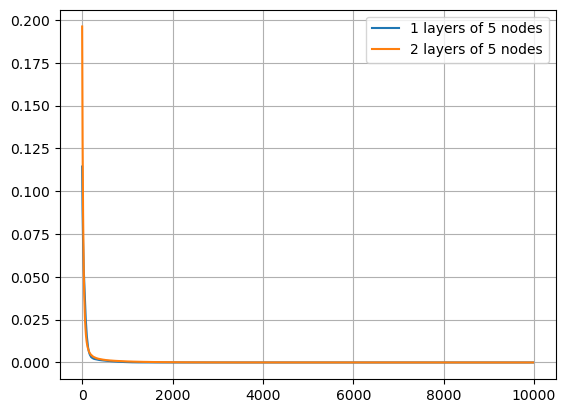

In [44]:
#laatste 3: learning_rate, epochs, batch size
#als batch size = len(inputs), dan betekent dit dus dat alle data getest wordt bij elke update van de weights en de biases

start = time.time()  
activations, weights, biases, cost_a = neural_network(inputs, outputs, [5], 1, 10000, len(inputs)) 
end = time.time()
print("Time taken for 1 layer of 5 nodes:", end - start, "seconds")

start = time.time()  
activations, weights, biases, cost_b = neural_network(inputs, outputs, [5, 5], 1, 10000, len(inputs)) 
end = time.time()
print("Time taken for 2 layes of 5 nodes:", end - start, "seconds")

plt.plot(cost_a[20:], label="1 layers of 5 nodes");
plt.plot(cost_b[20:], label="2 layers of 5 nodes");
plt.grid();
plt.legend();

Time taken for 1 layer of 5 nodes: 3.162214756011963 seconds
Time taken for 2 layes of 5 nodes: 3.9716238975524902 seconds
Time taken for 3 layers of 5 nodes: 4.848258972167969 seconds
Time taken for 4 layers of 5 nodes: 5.7274580001831055 seconds


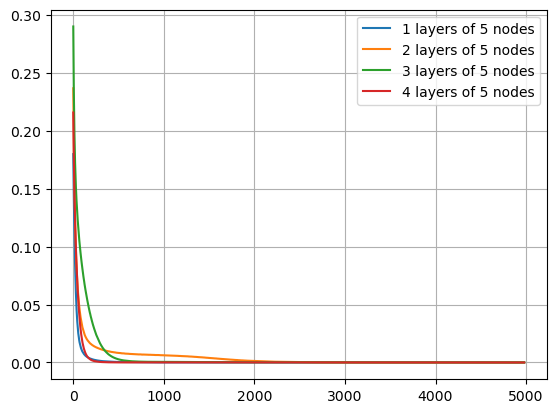

In [45]:
start = time.time()  
activations, weights, biases, cost_a = neural_network(inputs, outputs, [5], 1, 5000, len(inputs)) 
end = time.time()
print("Time taken for 1 layer of 5 nodes:", end - start, "seconds")

start = time.time()  
activations, weights, biases, cost_b = neural_network(inputs, outputs, [5, 5], 1, 5000, len(inputs)) 
end = time.time()
print("Time taken for 2 layes of 5 nodes:", end - start, "seconds")

start = time.time()  
activations, weights, biases, cost_c = neural_network(inputs, outputs, [5, 5, 5], 1, 5000, len(inputs)) 
end = time.time()
print("Time taken for 3 layers of 5 nodes:", end - start, "seconds")

start = time.time()  
activations, weights, biases, cost_d = neural_network(inputs, outputs, [5, 5, 5, 5], 1, 5000, len(inputs)) 
end = time.time()
print("Time taken for 4 layers of 5 nodes:", end - start, "seconds")

plt.plot(cost_a[20:], label="1 layers of 5 nodes");
plt.plot(cost_b[20:], label="2 layers of 5 nodes");
plt.plot(cost_c[20:], label="3 layers of 5 nodes");
plt.plot(cost_d[20:], label="4 layers of 5 nodes");
plt.grid();
plt.legend();

In [6]:
test_data = pd.read_csv("/Users/janvancauwenberghe/Desktop/DATA/eigen-projecten/neural-networks/mnist_test.csv")
train_data = pd.read_csv("/Users/janvancauwenberghe/Desktop/DATA/eigen-projecten/neural-networks/mnist_train.csv")

In [7]:
X_train = train_data.drop('label', axis=1).to_numpy()/255
y_train = pd.get_dummies(train_data['label']).astype(int).to_numpy()

X_test = test_data.drop('label', axis=1).to_numpy()/255
y_test = test_data['label']

In [8]:
def predict(inputs, weights, biases, labels):

    outputs = []

    for i in range(len(inputs)):

        activations = det_activations(inputs[i], weights, biases)
        outputs.append(labels[np.argmax(activations[-1])])

    return outputs

In [9]:
labels = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

In [10]:
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, classification_report

In [12]:
y_train[:2]

array([[0, 0, 0, 0, 0, 1, 0, 0, 0, 0],
       [1, 0, 0, 0, 0, 0, 0, 0, 0, 0]])

Using device: mps
Time taken: 343.82138085365295 seconds
Accuracy: 0.3017


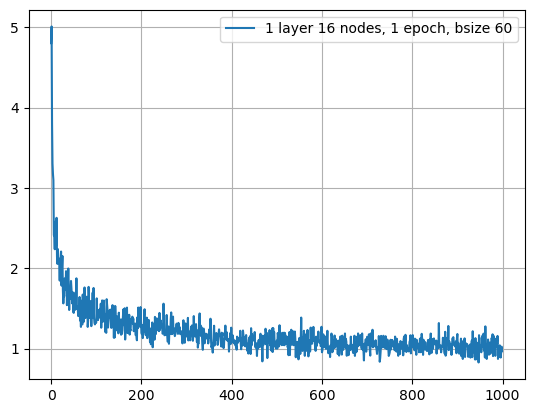

In [20]:
start = time.time()  
activations_0, weights_0, biases_0, cost_0 = neural_network(X_train, y_train, [16], 1, 1, 60) 
end = time.time()

print("Time taken:", end - start, "seconds")

plt.plot(cost_0, label="1 layer 16 nodes, 1 epoch, bsize 60");
plt.grid();
plt.legend();

y_predict_0 = predict(X_test, weights_0, biases_0, labels)
print('Accuracy: '+ str(accuracy_score(y_test,y_predict_0)))

Time taken: 1014.8840210437775 seconds
Accuracy: 0.5153


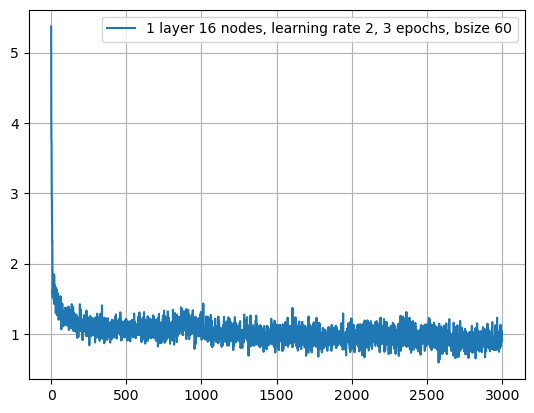

In [18]:
start = time.time()  
activations_2, weights_2, biases_2, cost_2 = neural_network(X_train, y_train, [16], 2, 3, 60) 
end = time.time()

print("Time taken:", end - start, "seconds")

plt.plot(cost_2, label="1 layer 16 nodes, learning rate 2, 3 epochs, bsize 60");
plt.grid();
plt.legend();

y_predict_2 = predict(X_test, weights_2, biases_2, labels)
print('Accuracy: '+ str(accuracy_score(y_test,y_predict_2)))

In [22]:
y_predict_2bis = predict(X_train, weights_2, biases_2, labels)
y_train = train_data['label']
print('Accuracy: '+ str(accuracy_score(y_train,y_predict_2bis)))

Accuracy: 0.5045666666666667


Time taken: 1346.4479229450226 seconds
Accuracy: 0.5743


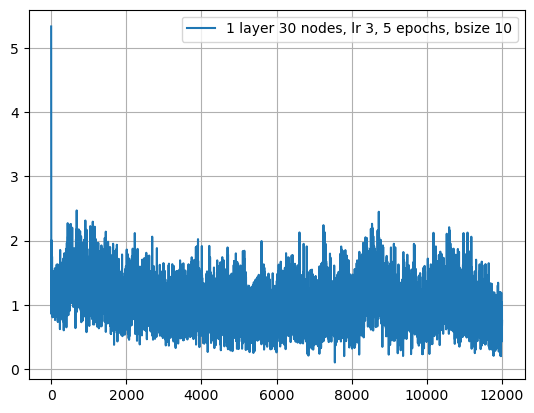

In [54]:
start = time.time()  
activations_4, weights_4, biases_4, cost_4 = neural_network(X_train, y_train, [30], 3, 2, 10) 
end = time.time()

print("Time taken:", end - start, "seconds")

plt.plot(cost_4, label="1 layer 30 nodes, lr 3, 5 epochs, bsize 10");
plt.grid();
plt.legend();

y_predict_4 = predict(X_test, weights_4, biases_4, labels)
print('Accuracy: '+ str(accuracy_score(y_test,y_predict_4)))

Time taken: 1329.4965407848358 seconds
Accuracy: 0.6086


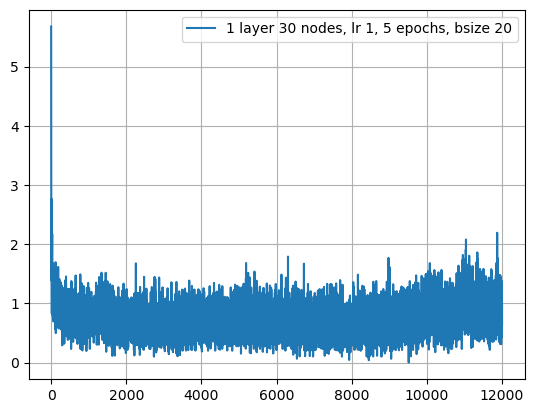

In [55]:
start = time.time()  
activations_5, weights_5, biases_5, cost_5 = neural_network(X_train, y_train, [30], 2, 2, 10) 
end = time.time()

print("Time taken:", end - start, "seconds")

plt.plot(cost_5, label="1 layer 30 nodes, lr 1, 5 epochs, bsize 20");
plt.grid();
plt.legend();

y_predict_5 = predict(X_test, weights_5, biases_5, labels)
print('Accuracy: '+ str(accuracy_score(y_test,y_predict_5)))

In [56]:
y_test[4231:4241]

4231    8
4232    1
4233    5
4234    3
4235    9
4236    5
4237    9
4238    7
4239    6
4240    9
Name: label, dtype: int64

In [57]:
y_predict_2[4231:4241]

[0, 1, 5, 3, 9, 5, 9, 3, 6, 9]

Time taken: 1081.5163900852203 seconds
Accuracy: 0.5239


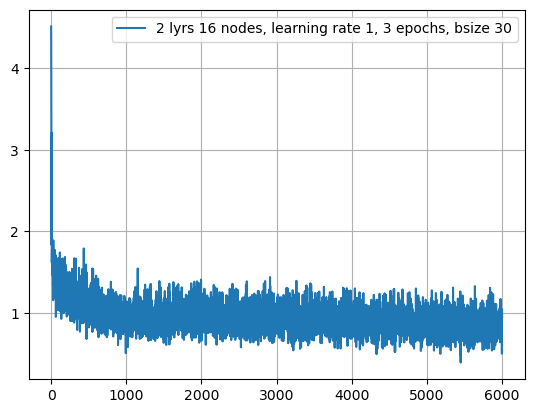

In [58]:
start = time.time()  
activations_6, weights_6, biases_6, cost_6 = neural_network(X_train, y_train, [16, 16], 1, 3, 30) 
end = time.time()

print("Time taken:", end - start, "seconds")

plt.plot(cost_6, label="2 lyrs 16 nodes, learning rate 1, 3 epochs, bsize 30");
plt.grid();
plt.legend();

y_predict_6 = predict(X_test, weights_6, biases_6, labels)
print('Accuracy: '+ str(accuracy_score(y_test,y_predict_6)))

Time taken: 1752.1690130233765 seconds
Accuracy: 0.7537


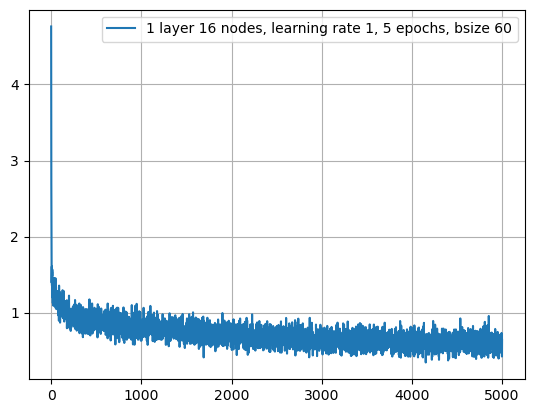

In [59]:
start = time.time()  
activations_6, weights_6, biases_6, cost_6 = neural_network(X_train, y_train, [16], 1, 5, 60) 
end = time.time()

print("Time taken:", end - start, "seconds")

plt.plot(cost_6, label="1 layer 16 nodes, learning rate 1, 5 epochs, bsize 60");
plt.grid();
plt.legend();

y_predict_6 = predict(X_test, weights_6, biases_6, labels)
print('Accuracy: '+ str(accuracy_score(y_test,y_predict_6)))

In [24]:
X_train = train_data.drop('label', axis=1).to_numpy()[:50001]/255
y_train = pd.get_dummies(train_data['label']).astype(int).to_numpy()[:50001]

In [ ]:
start = time.time()  
activations_7, weights_7, biases_7, cost_7 = neural_network(X_train, y_train, [30], 3, 30, 10) 
end = time.time()

print("Time taken:", end - start, "seconds")

plt.plot(cost_6, label="1 layer 16 nodes, learning rate 1, 5 epochs, bsize 60");
plt.grid();
plt.legend();

y_predict_6 = predict(X_test, weights_6, biases_6, labels)
print('Accuracy: '+ str(accuracy_score(y_test,y_predict_6)))

In [25]:
import platform
print(platform.processor())  # CPU model

i386


In [26]:
import cpuinfo
print(cpuinfo.get_cpu_info()['brand_raw'])

Intel(R) Core(TM) i5-7600 CPU @ 3.50GHz


In [27]:
import psutil
print(psutil.virtual_memory().total / 1e9, "GB RAM")

8.589934592 GB RAM


In [28]:
import os
print(os.name)  # 'posix' (Linux/macOS) or 'nt' (Windows)

posix


In [3]:
import torch
print("Torch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU detected")

Torch version: 2.2.2
CUDA available: False
GPU: No GPU detected


In [4]:
print("MPS available:", torch.backends.mps.is_available())

MPS available: True
